## Divisive Clustering

Top to bottom approach

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import os
os.environ['OMP_NUM_THREADS'] = '1'


In [3]:
df = pd.read_csv(r"C:\Users\Karan\Downloads\Mall_Customers.csv")
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [4]:
x = df[['Annual Income (k$)',
       'Spending Score (1-100)']]
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [5]:
def divisive_clustering(x, n_clusters=5):
    history = []
    labels = np.zeros(len(x),dtype=int)
    history.append(labels.copy())
    clusters = [np.arange(len(x))]
    while len(clusters) < n_clusters:
        sse_values = []
        for i in clusters:
            points = x[i]
            center = points.mean(axis=0)
            sse = np.sum((points-center)**2)
            sse_values.append(sse)

        split_idx = np.argmax(sse_values)
        point_idx = clusters.pop(split_idx)
        kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
        sublabel = kmeans.fit_predict(x[point_idx])
        cls1 = point_idx[sublabel==0]
        cls2 = point_idx[sublabel==1]
        clusters.append(cls1)
        clusters.append(cls2)

        labels = np.empty(len(x), int)
        for cluster_id, idx in enumerate(clusters):
            labels[idx] = cluster_id
        history.append(labels.copy())
    return history
    

label = divisive_clustering(x_scaled)
df['clusters'] = label[-1]
df

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),clusters
0,1,Male,19,15,39,3
1,2,Male,21,15,81,1
2,3,Female,20,16,6,3
3,4,Female,23,16,77,1
4,5,Female,31,17,40,3
...,...,...,...,...,...,...
195,196,Female,35,120,79,2
196,197,Female,45,126,28,0
197,198,Male,32,126,74,2
198,199,Male,32,137,18,0


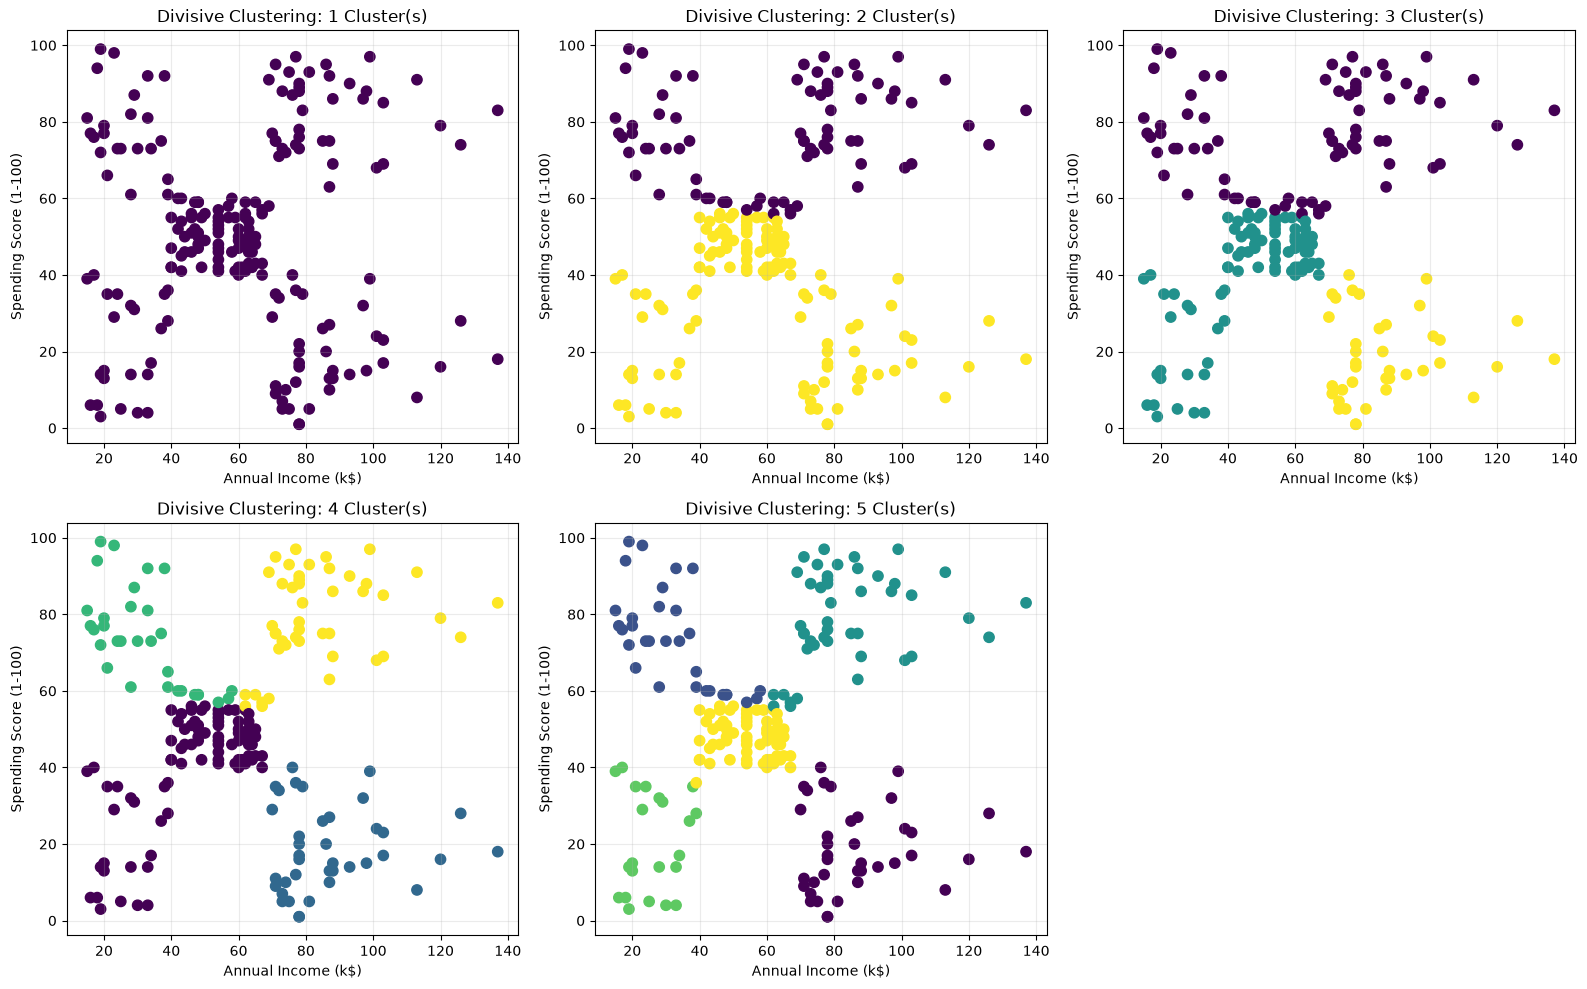

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, labels in enumerate(label):
    axes[i].scatter(x["Annual Income (k$)"],x["Spending Score (1-100)"],c=labels,cmap="viridis",s=55)
    axes[i].set_title(f"Divisive Clustering: {i + 1} Cluster(s)")
    axes[i].set_xlabel("Annual Income (k$)")
    axes[i].set_ylabel("Spending Score (1-100)")
    axes[i].grid(alpha=0.25)
axes[5].axis("off")
plt.tight_layout()
plt.show()

## Agglomerative Clustering

In [ ]:
from sklearn.cluster import AgglomerativeClustering
df = pd.read_csv(r"C:\Users\Karan\Downloads\Mall_Customers.csv")

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [9]:
x = df[['Annual Income (k$)', 'Spending Score (1-100)']]
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [10]:
history = []
for k in [10,9,8,7,6,5]:
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(x_scaled)
    history.append((k, labels))

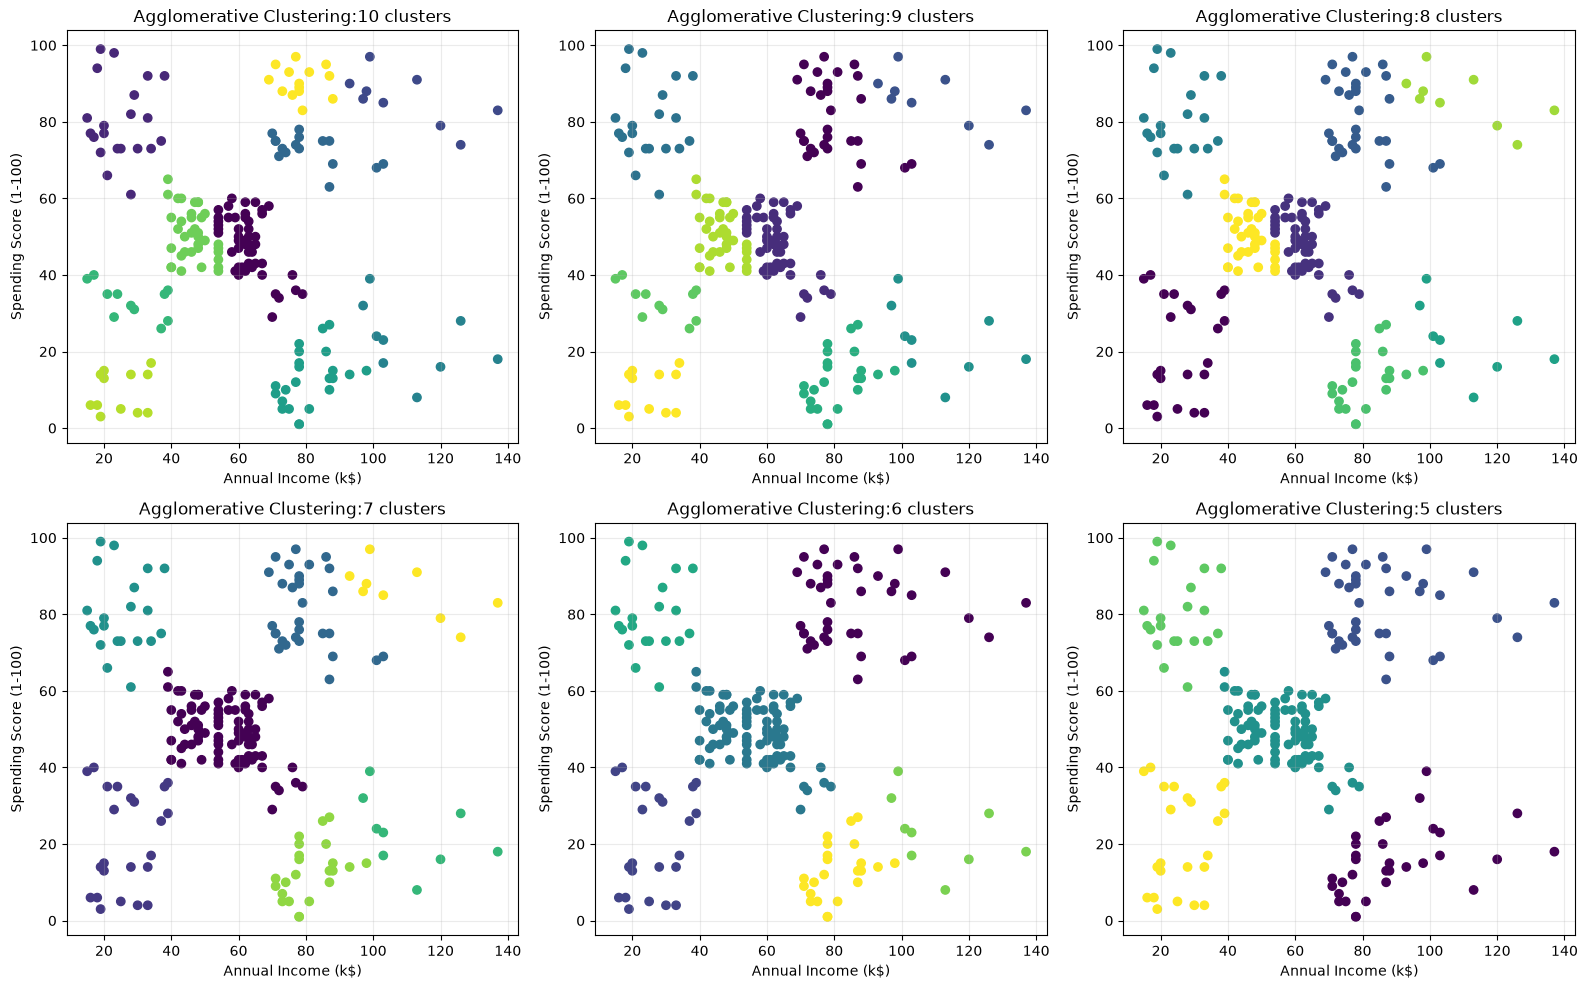

In [15]:
fig, axes = plt.subplots(2,3, figsize=(16,10))
axes = axes.flatten()
for i, (k,labels) in enumerate(history):
    axes[i].scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=labels, cmap='viridis')
    axes[i].set_title(f'Agglomerative Clustering:{k} clusters')
    axes[i].set_xlabel('Annual Income (k$)')
    axes[i].set_ylabel('Spending Score (1-100)')
    axes[i].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [16]:
from scipy.cluster.hierarchy import dendrogram, linkage

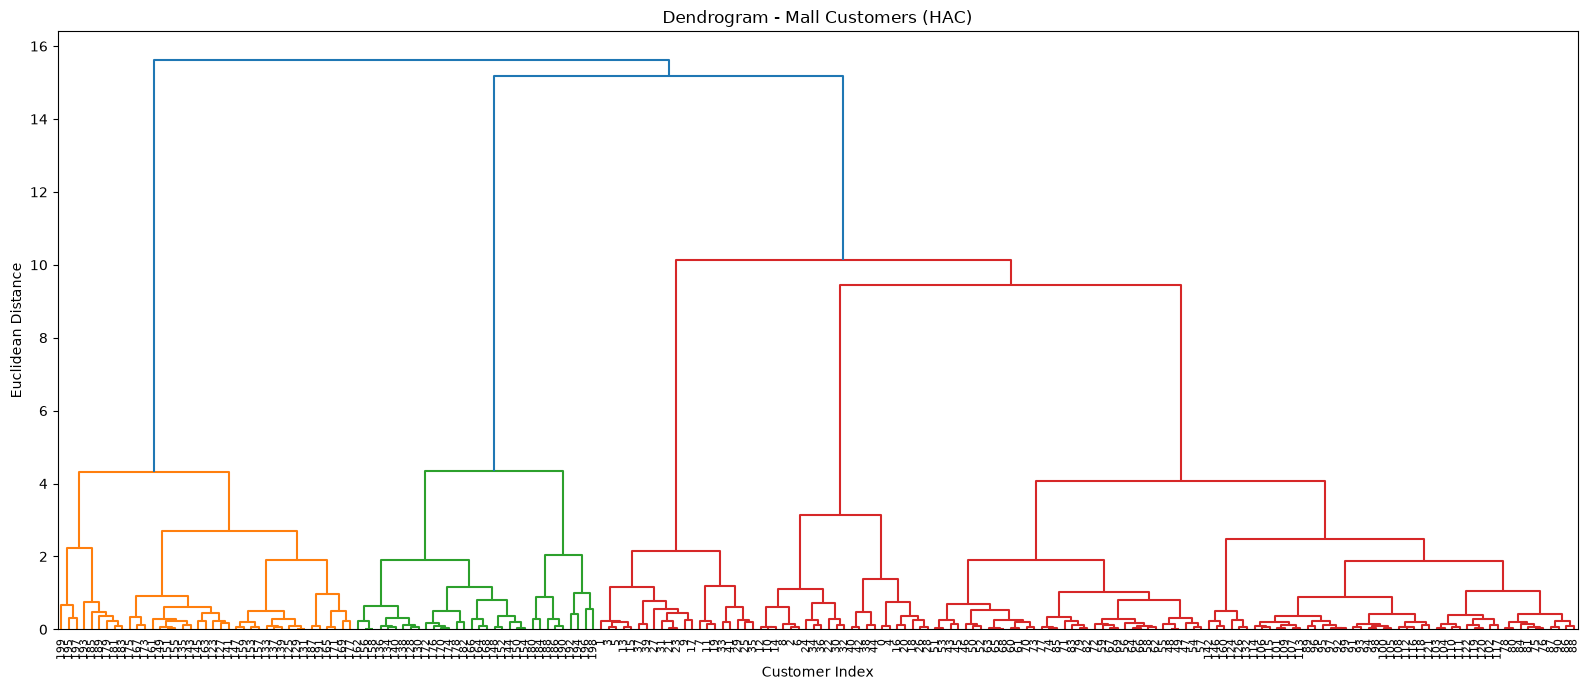

In [17]:
Z = linkage(x_scaled, method="ward")

plt.figure(figsize=(16, 7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=8)

plt.title("Dendrogram - Mall Customers (HAC)")
plt.xlabel("Customer Index")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()